# Layer projected DOS

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from src.latexfig import LatexFigure
from ase.optimize import BFGS
from calorine.calculators import CPUNEP
from calorine.tools import get_force_constants
from src.structure import Perovskite, is_atom_bulk, get_layers
from src.structureoptimizer import opt_filter
from src.phononASE import is_phonon_bulk, phonon_to_atoms

In [59]:
def relax_atoms(atoms, nep_txt='examples/nep.txt', filt=True, fmax=0.01, mask=None, strained=False):

    calc = CPUNEP(nep_txt)

    # Attach the calculator to the atoms object
    atoms.calc = calc

    # Apply filter to optimize unit cell parameters and atomic positions if filt is True
    # Otherwise only optimize atomic positions
    if filt:
        atoms_filt = opt_filter(atoms, strained, mask)
    else:
        atoms_filt = atoms
    
    # Set up the BFGS optimizer on all processes
    opt = BFGS(atoms_filt)
    # Run the optimization until forces are smaller than fmax
    opt.run(fmax=fmax*1.e-3)

def calculate_phonon(atoms, nep_txt='examples/nep.txt', Nc=2):
    calc = CPUNEP(nep_txt)
    atoms = atoms.copy()
    atoms.calc = calc
    if is_atom_bulk(atoms):
        supercell = [Nc, Nc, Nc]
    else:
        supercell = [Nc, Nc, 1]
    phonon = get_force_constants(atoms, calc, supercell)
    return phonon

In [64]:
from ase.visualize import view

In [65]:
view(atoms)

<Popen: returncode: None args: ['/home/tbrav/projects/OxideSlabs2/.venv/bin/...>

In [60]:
# Calculate phonons for the bulk unit cell structure using the trained NEP model
perovskite = Perovskite('BaTiO3', bulk=False, dslab=4.5)
atoms = perovskite.atoms.copy()
relax_atoms(atoms)
phonon = calculate_phonon(atoms)

      Step     Time          Energy          fmax
BFGS:    0 16:08:15     -202.679622        2.232477
BFGS:    1 16:08:15     -202.850394        1.587527
BFGS:    2 16:08:15     -203.046935        0.954508
BFGS:    3 16:08:15     -203.099243        0.555860
BFGS:    4 16:08:15     -203.154280        0.506429
BFGS:    5 16:08:15     -203.187128        0.422586
BFGS:    6 16:08:15     -203.202323        0.368015
BFGS:    7 16:08:15     -203.226361        0.415403
BFGS:    8 16:08:15     -203.246205        0.376625
BFGS:    9 16:08:15     -203.266641        0.269799
BFGS:   10 16:08:15     -203.278251        0.190663
BFGS:   11 16:08:16     -203.285455        0.117711
BFGS:   12 16:08:16     -203.288693        0.078910
BFGS:   13 16:08:16     -203.290001        0.099768
BFGS:   14 16:08:16     -203.290708        0.069800
BFGS:   15 16:08:16     -203.291181        0.059497
BFGS:   16 16:08:16     -203.291503        0.048007
BFGS:   17 16:08:16     -203.291780        0.049315
BFGS:   18 16:

In [66]:
def get_phonon_pdos(phonon, per_layer=False, tol=0.15):
    bulk = is_phonon_bulk(phonon)
    # Load Phonopy object from YAML file
    if bulk == True:
        symbols = phonon.unitcell.symbols
        # Set symmetric mesh for bulk
        phonon.run_mesh([30, 30, 30], with_eigenvectors=True, is_mesh_symmetry=False)
    else:
        symbols = phonon.unitcell.symbols
        # Set asymmetric mesh for slab
        phonon.run_mesh([30, 30, 1], with_eigenvectors=True, is_mesh_symmetry=False)
    # Run PDOS calculations and extract values
    phonon.run_projected_dos()
    PDOS = phonon.get_projected_dos_dict()
    pdos = PDOS['projected_dos']
    freq = PDOS['frequency_points']

    if per_layer:
        atoms = phonon_to_atoms(phonon)
        layers = get_layers(atoms, tol=tol)
    else:
        layers = [list(range(len(symbols)))]  # Single layer containing all atoms
    # Group PDOS by layer and element (symbol) and sum over all atoms of the same element in each layer
    pdos_grouped = {}
    unique_symbols = sorted(set(symbols))

    for l, layer in enumerate(layers):
        layer_symbols = [symbols[i] for i in layer]
        layer_pdos = pdos[layer, :]

        pdos_grouped[l] = {}

        for symbol in unique_symbols:
            indices = [i for i, s in enumerate(layer_symbols) if s == symbol]

            if indices:
                pdos_grouped[l][symbol] = np.sum(layer_pdos[indices], axis=0)
    
    # Returns PDOS (states/THz) and frequencies (THz)
    return pdos_grouped, freq

In [12]:
layers = get_layers(atoms)

In [13]:
layers

[array([ 2,  3, 10]),
 array([0, 6]),
 array([ 5,  4, 11]),
 array([9, 1]),
 array([12,  8,  7])]

In [5]:
# Print dictionary keys to verify the structure of the PDOS data
pdos_grouped, freq = get_phonon_pdos(phonon, per_layer=True)

In [8]:
len(pdos_grouped.keys())

5

In [24]:
def _plot_pdos(ax, phonon, per_layer=False):
    atom_colors = {'Ba': '#00c900', 'Sr': "#d3aaff",
                    'Ti': '#89d2ff', 'O': '#ff0d0d'}
    # Extract PDOS data
    pdosx, pdosy = get_phonon_pdos(phonon, per_layer)
    symbols = list(pdosx.keys())
    # Plot PDOS
    for symbol in symbols:
        ax.plot(pdosx[symbol], pdosy, lw=1, color=atom_colors[symbol], label=f'{symbol}')
    # Add legend to the PDOS plot
    ax.legend()

In [104]:
def plot_layer_pdos(phonon, width=1, AR=None):
    """Function to plot the phonon dispersion and DOS together.
    
    Parameters:
        - phonon: Phonon object containing phonon data.
        - width: Width of the figure as a fraction of the total width.
    
    Returns:
        - None. The function creates a plot of the phonon dispersion and DOS.
    """

    # Define tickmarks for the x- and y-axis
    E_tickmarks = np.arange(-10, 31, 5)
    # Convert tickmarks to strings with i for negative numbers
    E_ticklabels = []
    for tick in E_tickmarks:
        if tick < 0:
            E_ticklabels.append(f'{abs(tick)}i')
        else:
            E_ticklabels.append(f'{tick}')

    # Define tickmarks for the x- and y-axis
    dos_tickmarks = np.arange(0, 4, 1)

    pdos_grouped, freq = get_phonon_pdos(phonon, per_layer=True)

    N_layers = len(pdos_grouped.keys())
    
    # Make a simple figure where graphs are plotted
    lf = LatexFigure()
    
    if AR is None:
        AR = 1
    fig, axes = lf.create(width=width, AR=AR, subplots=(1, N_layers), minor=False, sharey='col')
    

    def _plot_pdos(ax, pdosx, pdosy):
        atom_colors = {'Ba': '#00c900', 'Sr': "#d3aaff",
                       'Ti': '#89d2ff', 'O': '#ff0d0d'}
        # Extract PDOS data
        symbols = list(pdosx.keys())
        # Plot PDOS
        for symbol in symbols:
            ax.plot(pdosx[symbol], pdosy, lw=1, color=atom_colors[symbol], label=f'{symbol}')
        # Add legend to the PDOS plot
        #ax.legend()

    # Plot dispersion for each phonon object in a separate subplot
    axes[0].set_ylabel('Frequency (THz)')
    # Cycle through the bands
    for i in range(N_layers):
        # Plot dashed line at Fermi level for all subplots
        axes[i].axhline(y=0, color='k', linestyle=':', lw=0.8)
        # Plot pdos for all layers
        
        _plot_pdos(axes[i], pdos_grouped[i], freq)

        # Add title
        axes[i].set_title(f'layer {i+1}')
        # Set x-label
        #axes[i].set_xlabel('DOS (1/THz)')
        # Add legend to the DOS plot
        #axes[i].legend(loc='upper right')
        # Add minor tickmarks to the x- and y-axis
        axes[i].xaxis.set_minor_locator(AutoMinorLocator())
        axes[i].yaxis.set_minor_locator(AutoMinorLocator())

        # Force x- and y-ticks
        axes[i].set_xticks(dos_tickmarks[0:-1], dos_tickmarks[0:-1].astype(str))
        axes[i].set_yticks(E_tickmarks, E_ticklabels)
        # Set limits to match
        axes[i].set_xlim(dos_tickmarks[0], dos_tickmarks[-1])
        axes[i].set_ylim(E_tickmarks[0], E_tickmarks[-1])
        if i != 0:
            # Hide y-tick labels
            axes[i].set_yticklabels([])

    # Gather handles and labels from ALL axes in the figure
    lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes]
    handles, labels = [sum(ll, []) for ll in zip(*lines_labels)]

    # De-duplicate using a dictionary
    unique_legend = dict(zip(labels, handles))

    # Create a single figure-level legend
    fig.legend(
        unique_legend.values(),
        unique_legend.keys(),
        loc="outside right",
        ncol=1
    )
    
    fig.set_constrained_layout_pads(wspace=0.0, w_pad=0.0)
    #fig.legend()
    fig.supxlabel('DOS (1/THz)', fontsize=8)
    return fig

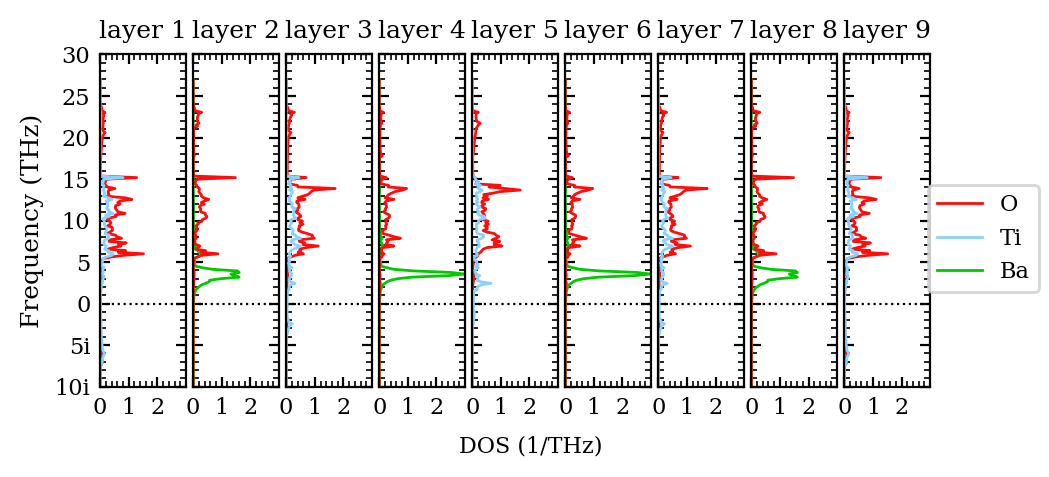

In [105]:
fig = plot_layer_pdos(phonon, AR=4)